# Furniture Sales Analysis & Delivery Risk Prediction

**End-to-end data science project** analyzing sales performance of a custom
furniture manufacturer (Poland, 2024–2025), with two machine learning models:

1. **Regression** — predict order revenue
2. **Classification** — predict delivery delay risk *before production starts*

Dataset: synthetically generated, 4,200 orders, grounded in real domain
knowledge of the custom furniture industry.

**Tech stack:** `pandas` · `numpy` · `scikit-learn` · `matplotlib` · `seaborn`


## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)


In [2]:
df = pd.read_csv("../data/furniture_sales.csv", parse_dates=["order_date"])
df["month"] = df["order_date"].dt.to_period("M").astype(str)
print(df.shape)
df.head()


(4200, 18)


,order_id,order_date,category,material,region,sales_channel,customer_type,is_custom_order,quantity,unit_price,discount_pct,revenue,planned_production_days,planned_delivery_days,actual_delivery_days,is_delayed,customer_satisfaction,month
0,102880,2024-01-01,Ліжко,Дуб,Варшава,Шоурум,Роздрібний,1,1,1675.13,0.018,1644.98,30,35,47,1,2.7,2024-01
1,103151,2024-01-01,Шафа,Метал + скло,Вроцлав,Шоурум,Дизайнер,0,1,991.05,0.034,957.35,13,15,15,0,4.4,2024-01
2,103453,2024-01-01,Ліжко,Шпон,Варшава,Дилер,Роздрібний,0,2,1033.01,0.026,2012.30,14,16,16,0,4.8,2024-01
3,103503,2024-01-01,Стіл,Дуб,Варшава,Шоурум,Роздрібний,1,1,1010.85,0.044,966.37,27,29,39,1,3.1,2024-01
4,101837,2024-01-01,Кухня на замовлення,Метал + скло,Гданськ,Шоурум,Дизайнер,1,1,2473.17,0.049,2351.98,21,22,22,0,4.2,2024-01


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 4200 non-null   int64         
 1   order_date               4200 non-null   datetime64[us]
 2   category                 4200 non-null   str           
 3   material                 4200 non-null   str           
 4   region                   4200 non-null   str           
 5   sales_channel            4200 non-null   str           
 6   customer_type            4200 non-null   str           
 7   is_custom_order          4200 non-null   int64         
 8   quantity                 4200 non-null   int64         
 9   unit_price               4200 non-null   float64       
 10  discount_pct             4200 non-null   float64       
 11  revenue                  4200 non-null   float64       
 12  planned_production_days  4200 non-null   int6

## 2. Exploratory Data Analysis

Let's look at overall business performance first, then dig into
seasonality, category/region breakdowns, and what drives delivery delays.


In [4]:
print(f"Period: {df['order_date'].min().date()} -- {df['order_date'].max().date()}")
print(f"Orders: {len(df):,}")
print(f"Total revenue: {df['revenue'].sum():,.0f} PLN")
print(f"Average order value: {df['revenue'].mean():,.0f} PLN")
print(f"Delayed deliveries: {df['is_delayed'].mean()*100:.1f}%")
print(f"Average customer satisfaction: {df['customer_satisfaction'].mean():.2f} / 5")


Period: 2024-01-01 -- 2025-12-31
Orders: 4,200
Total revenue: 13,374,370 PLN
Average order value: 3,184 PLN
Delayed deliveries: 36.7%
Average customer satisfaction: 3.94 / 5


### 2.1 Revenue seasonality

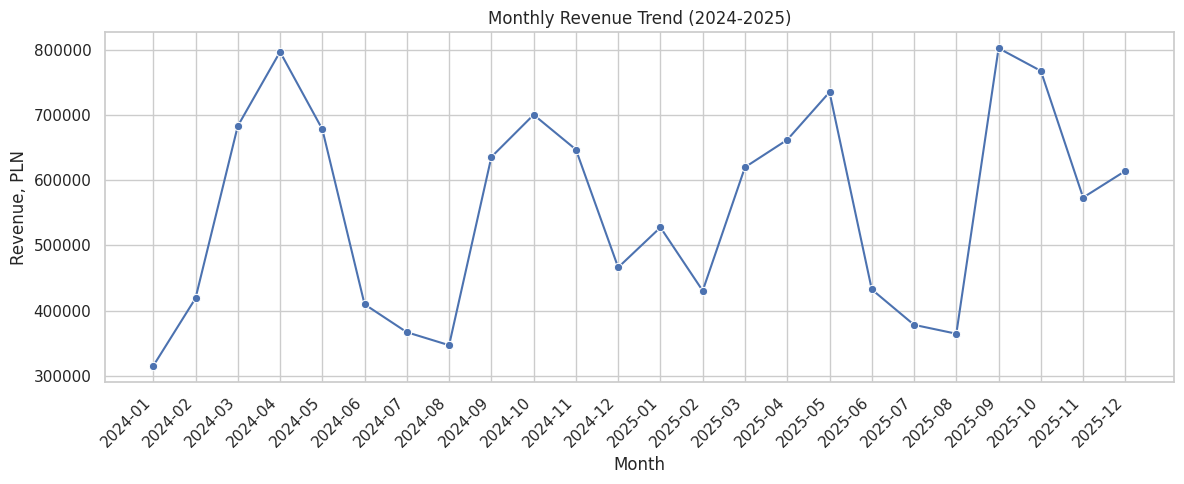

In [5]:
monthly = df.groupby("month")["revenue"].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="month", y="revenue", marker="o")
plt.xticks(rotation=45, ha="right")
plt.title("Monthly Revenue Trend (2024-2025)")
plt.ylabel("Revenue, PLN")
plt.xlabel("Month")
plt.tight_layout()
plt.show()


Clear seasonality: demand peaks in **spring (Mar-Apr)** and
**autumn (Sep-Oct)** — matching the typical home-renovation cycle — with
a summer slowdown. There's also visible year-over-year growth into 2025.

### 2.2 Revenue by category & orders by region

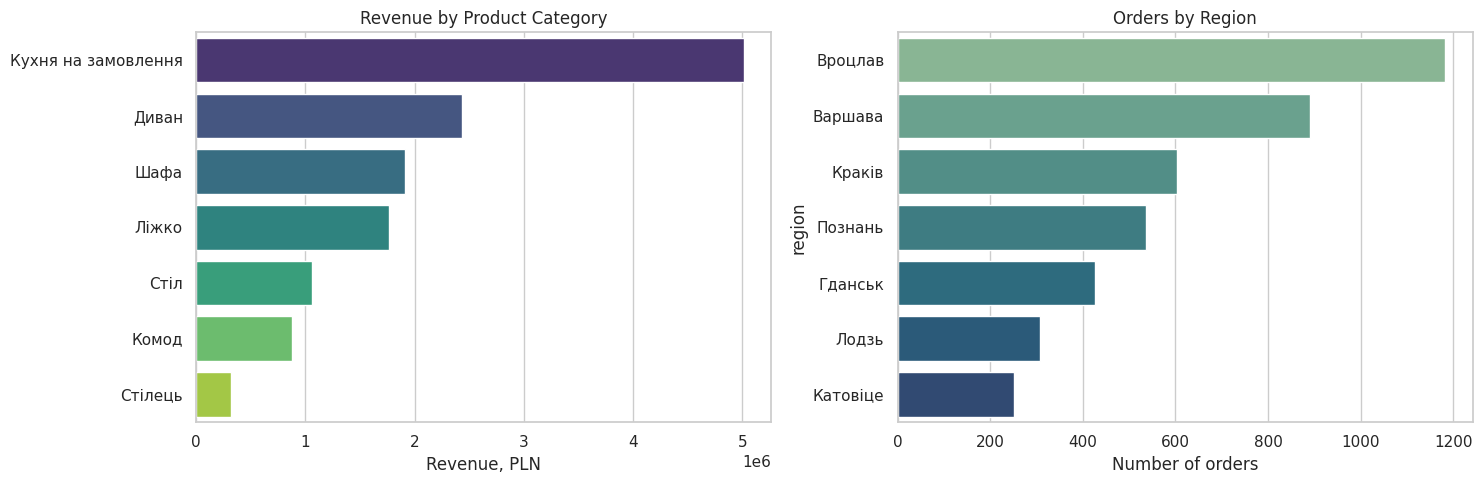

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cat_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_revenue, x="revenue", y="category", palette="viridis",
            hue="category", legend=False, ax=axes[0])
axes[0].set_title("Revenue by Product Category")
axes[0].set_xlabel("Revenue, PLN")
axes[0].set_ylabel("")

region_counts = df["region"].value_counts()
sns.barplot(x=region_counts.values, y=region_counts.index, palette="crest",
            hue=region_counts.index, legend=False, ax=axes[1])
axes[1].set_title("Orders by Region")
axes[1].set_xlabel("Number of orders")

plt.tight_layout()
plt.show()


### 2.3 What drives delivery delays?

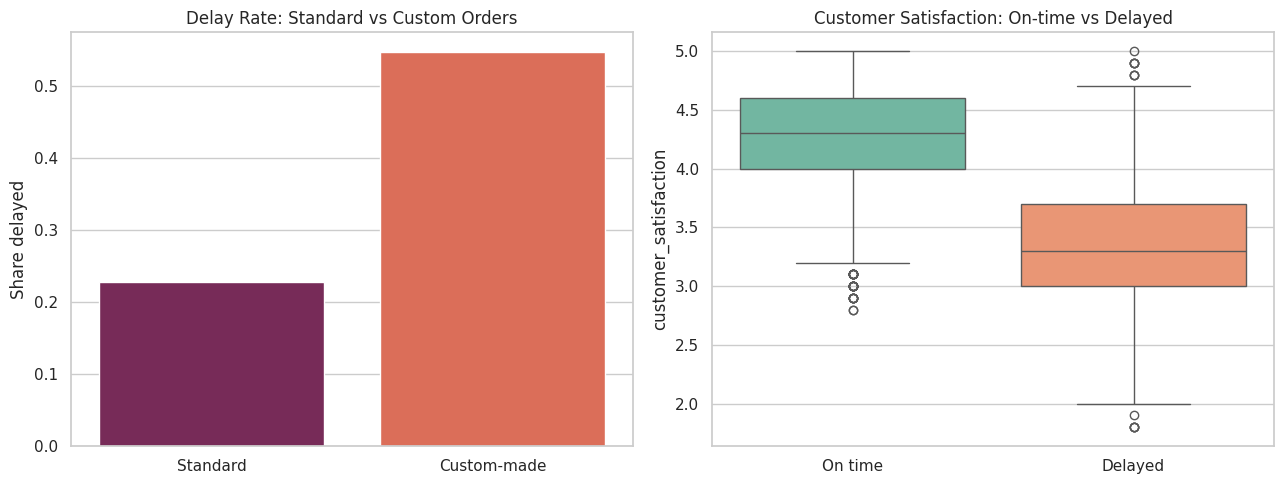

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

delay_by_custom = df.groupby("is_custom_order")["is_delayed"].mean().reset_index()
delay_by_custom["is_custom_order"] = delay_by_custom["is_custom_order"].map(
    {0: "Standard", 1: "Custom-made"})
sns.barplot(data=delay_by_custom, x="is_custom_order", y="is_delayed",
            palette="rocket", hue="is_custom_order", legend=False, ax=axes[0])
axes[0].set_title("Delay Rate: Standard vs Custom Orders")
axes[0].set_ylabel("Share delayed")
axes[0].set_xlabel("")

sns.boxplot(data=df, x="is_delayed", y="customer_satisfaction",
            palette="Set2", hue="is_delayed", legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["On time", "Delayed"])
axes[1].set_title("Customer Satisfaction: On-time vs Delayed")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()


**Key insight:** custom-made orders are delayed far more often than
standard catalog orders, and delays clearly tank customer satisfaction.
This is exactly the pattern we'll try to predict in Section 4.

### 2.4 Correlation overview

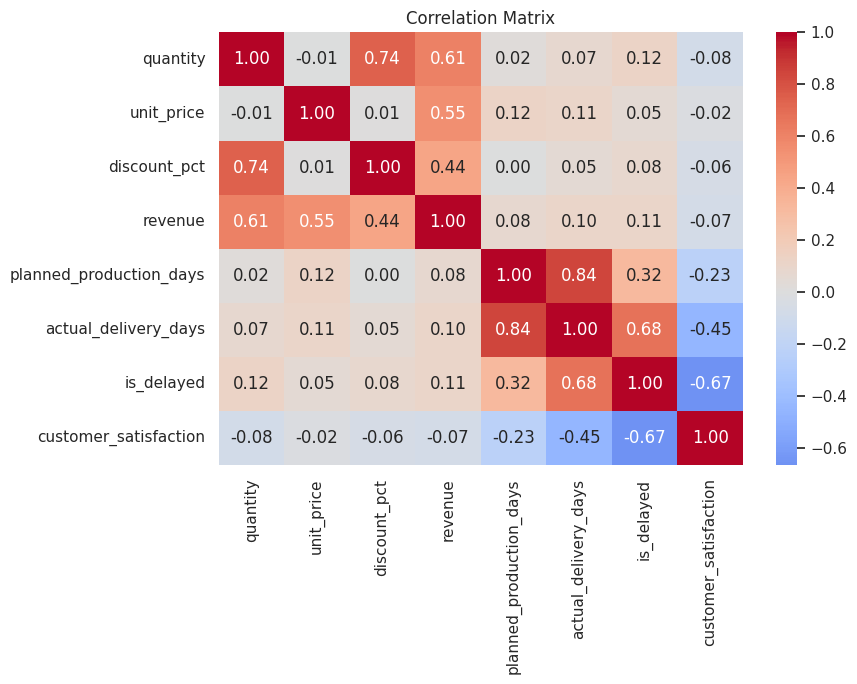

In [8]:
num_cols = ["quantity", "unit_price", "discount_pct", "revenue",
            "planned_production_days", "actual_delivery_days",
            "is_delayed", "customer_satisfaction"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


## 3. ML Model 1 — Predicting Order Revenue (Regression)

We'll compare a simple baseline (`LinearRegression`) against
`RandomForestRegressor`, using a `ColumnTransformer` + `Pipeline` to handle
categorical encoding cleanly.


In [9]:
features_reg = [
    "category", "material", "region", "sales_channel", "customer_type",
    "is_custom_order", "quantity", "unit_price", "discount_pct",
]
target_reg = "revenue"

X = df[features_reg]
y = df[target_reg]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = ["category", "material", "region", "sales_channel", "customer_type"]

preprocess_reg = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], remainder="passthrough")

reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
}

reg_results = []
reg_predictions = {}

for name, model in reg_models.items():
    pipe = Pipeline([("prep", preprocess_reg), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    reg_predictions[name] = pred

    reg_results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })
    if name == "Random Forest":
        best_reg_pipe = pipe

pd.DataFrame(reg_results)


,model,MAE,RMSE,R2
0,Linear Regression,1446.963424,3103.863526,0.678886
1,Random Forest,122.044717,472.747975,0.992551


Revenue is largely a deterministic function of `unit_price`,
`quantity`, and `discount_pct`, so the Random Forest's near-perfect R²
is expected — this task mainly demonstrates a clean encoding + modeling
pipeline rather than a hard prediction problem.

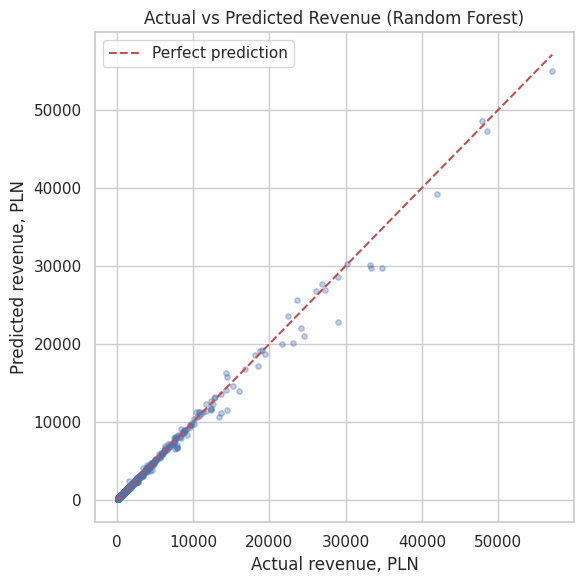

In [10]:
best_reg_name = "Random Forest"
plt.figure(figsize=(6, 6))
plt.scatter(y_test, reg_predictions[best_reg_name], alpha=0.35, s=15)
lims = [0, max(y_test.max(), reg_predictions[best_reg_name].max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual revenue, PLN")
plt.ylabel("Predicted revenue, PLN")
plt.title(f"Actual vs Predicted Revenue ({best_reg_name})")
plt.legend()
plt.tight_layout()
plt.show()


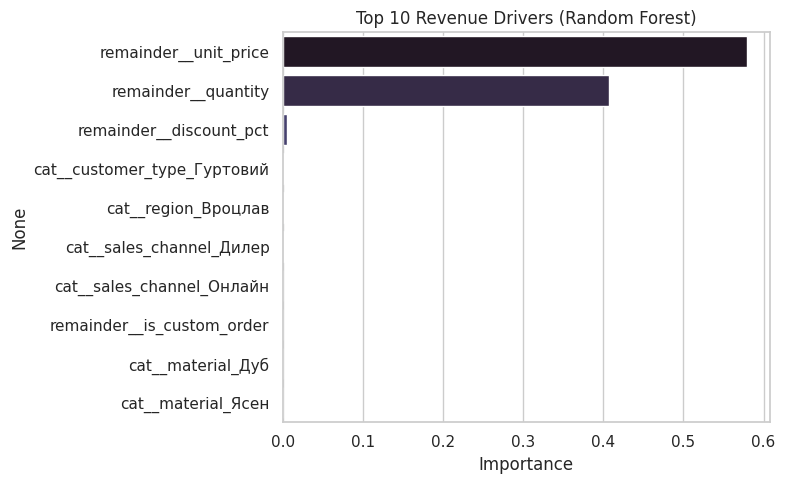

In [11]:
rf_model = best_reg_pipe.named_steps["model"]
feature_names = best_reg_pipe.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf_model.feature_importances_, index=feature_names) \
                .sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette="mako",
            hue=importances.index, legend=False)
plt.title("Top 10 Revenue Drivers (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 4. ML Model 2 — Predicting Delivery Delay Risk (Classification)

This is the **business-critical** model: can we flag high-risk orders
*at the moment they're placed*, before production even starts?

Important: we deliberately **exclude `actual_delivery_days`** from the
features — that column is only known *after* the delay already happened,
so including it would be data leakage. We only use information available
at order time.


In [12]:
features_clf = [
    "category", "material", "region", "sales_channel", "customer_type",
    "is_custom_order", "quantity", "unit_price", "discount_pct",
    "planned_production_days", "planned_delivery_days",
]
target_clf = "is_delayed"

Xc = df[features_clf]
yc = df[target_clf]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

preprocess_clf = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], remainder="passthrough")

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, random_state=42, n_jobs=-1,
        class_weight="balanced",
    ),
}

roc_data = {}
best_auc, best_clf_pipe, best_clf_name = -1, None, None

for name, model in clf_models.items():
    pipe = Pipeline([("prep", preprocess_clf), ("model", model)])
    pipe.fit(Xc_train, yc_train)
    proba = pipe.predict_proba(Xc_test)[:, 1]

    auc = roc_auc_score(yc_test, proba)
    fpr, tpr, _ = roc_curve(yc_test, proba)
    roc_data[name] = (fpr, tpr, auc)

    print(f"--- {name} (ROC-AUC: {auc:.3f}) ---")
    print(classification_report(yc_test, pipe.predict(Xc_test), target_names=["On time", "Delayed"]))

    if auc > best_auc:
        best_auc, best_clf_pipe, best_clf_name = auc, pipe, name

print(f"Best model: {best_clf_name} (ROC-AUC = {best_auc:.3f})")


--- Logistic Regression (ROC-AUC: 0.738) ---
              precision    recall  f1-score   support

     On time       0.78      0.70      0.74       532
     Delayed       0.56      0.66      0.60       308

    accuracy                           0.68       840
   macro avg       0.67      0.68      0.67       840
weighted avg       0.70      0.68      0.69       840



--- Random Forest (ROC-AUC: 0.731) ---
              precision    recall  f1-score   support

     On time       0.78      0.71      0.74       532
     Delayed       0.56      0.65      0.60       308

    accuracy                           0.69       840
   macro avg       0.67      0.68      0.67       840
weighted avg       0.70      0.69      0.69       840

Best model: Logistic Regression (ROC-AUC = 0.738)


`class_weight="balanced"` matters a lot here: only ~25% of orders are
delayed, so without it, models learn to just predict "on time" for
everything and get ~75% accuracy while catching almost no real delays.
Balancing the class weights trades a bit of overall accuracy for much
better recall on the delayed class — which is the class we actually care
about business-wise.

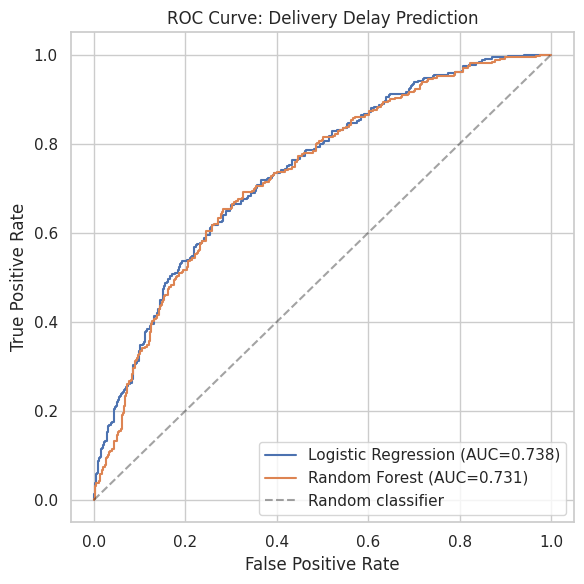

In [13]:
plt.figure(figsize=(6, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Delivery Delay Prediction")
plt.legend()
plt.tight_layout()
plt.show()


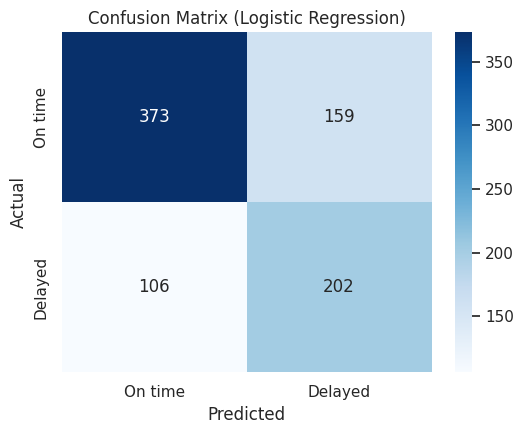

In [14]:
pred_best = best_clf_pipe.predict(Xc_test)
cm = confusion_matrix(yc_test, pred_best)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["On time", "Delayed"], yticklabels=["On time", "Delayed"])
plt.title(f"Confusion Matrix ({best_clf_name})")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()


In [15]:
if best_clf_name == "Random Forest":
    clf_model = best_clf_pipe.named_steps["model"]
    feat_names_clf = best_clf_pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(clf_model.feature_importances_, index=feat_names_clf) \
            .sort_values(ascending=False).head(10)

    plt.figure(figsize=(8, 5))
    sns.barplot(x=imp.values, y=imp.index, palette="flare", hue=imp.index, legend=False)
    plt.title("Top 10 Delay-Risk Drivers (Random Forest)")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Best model was Logistic Regression — see coefficients below instead of RF importances.")
    coefs = pd.Series(
        best_clf_pipe.named_steps["model"].coef_[0],
        index=best_clf_pipe.named_steps["prep"].get_feature_names_out()
    ).sort_values(key=abs, ascending=False).head(10)
    display(coefs)


Best model was Logistic Regression — see coefficients below instead of RF importances.


remainder__is_custom_order           1.370146
cat__material_ДСП/МДФ               -0.723154
cat__material_Дуб                    0.424043
cat__material_Сосна                 -0.405124
cat__sales_channel_Шоурум           -0.369139
cat__sales_channel_Онлайн           -0.259650
cat__customer_type_Дизайнер         -0.248979
cat__material_Ясен                   0.199376
cat__category_Кухня на замовлення    0.162037
cat__sales_channel_Дилер             0.160661
dtype: float64

## 5. Conclusions & Next Steps

**Business takeaways:**
- Revenue is highly seasonal (spring & autumn peaks) — useful for
  production capacity planning
- Custom-made orders and premium materials carry meaningfully higher
  delivery delay risk
- A delay-risk model with **ROC-AUC ≈ 0.74** can realistically flag
  ~2 out of 3 at-risk orders at order time — enough to justify proactive
  customer communication or production prioritization

**Possible next steps:**
- Time-series forecasting (Prophet / ARIMA) for monthly demand planning
- Hyperparameter tuning (`GridSearchCV`) for both models
- Deploy the delay-risk model as a small API (FastAPI) or a Streamlit demo
